# Logística e SLA

Análise de pedidos com foco em desempenho logístico. São avaliados:

- **Entrega no prazo (OTD):** percentual de pedidos entregues até a data estimada
- **Lead time por fase:** tempo de aprovação, postagem pelo seller e transporte
- **Impacto do atraso na satisfação:** relação entre dias de atraso e nota de avaliação
- **Desempenho por região e rota:** comparação entre UFs de origem (seller) e destino (cliente)



## 1. Importações

#### Instalando as bibliotecas

In [ ]:
%pip install pandas numpy matplotlib seaborn

#### Importando as bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carregamento dos dados

#### Carregando os CSVs

In [61]:
PASTA = "../data/"

orders    = pd.read_csv(PASTA + "olist_orders_dataset.csv")
items     = pd.read_csv(PASTA + "olist_order_items_dataset.csv")
reviews   = pd.read_csv(PASTA + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(PASTA + "olist_customers_dataset.csv")
sellers   = pd.read_csv(PASTA + "olist_sellers_dataset.csv")

#### Conferindo o tamanho das tabelas

In [62]:
print("orders:", orders.shape)
print("items:", items.shape)
print("reviews:", reviews.shape)
print("customers:", customers.shape)
print("sellers:", sellers.shape)

orders: (99441, 8)
items: (112650, 7)
reviews: (99224, 7)
customers: (99441, 5)
sellers: (3095, 4)


## 3. Tratamento dos dados

#### Convertendo datas e filtrando entregues

In [63]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col])

entregues = orders[orders["order_status"] == "delivered"].copy()

print("Total de pedidos:", len(orders))
print("Entregues:", len(entregues))

Total de pedidos: 99441
Entregues: 96478


#### Removendo nulos

In [64]:
antes = len(entregues)

entregues = entregues.dropna(subset=[
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
])

print("Removidos por data nula:", antes - len(entregues))
print("Restantes:", len(entregues))

Removidos por data nula: 23
Restantes: 96455


#### Calculando o tempo de cada fase

In [66]:
def dias(fim, inicio):
    return (fim - inicio).dt.total_seconds() / 86400

entregues["dias_aprovacao"]  = dias(entregues["order_approved_at"], entregues["order_purchase_timestamp"])
entregues["dias_postagem"]   = dias(entregues["order_delivered_carrier_date"], entregues["order_approved_at"])
entregues["dias_transporte"] = dias(entregues["order_delivered_customer_date"], entregues["order_delivered_carrier_date"])
entregues["dias_total"]      = dias(entregues["order_delivered_customer_date"], entregues["order_purchase_timestamp"])

#### Removendo negativos

In [67]:
negativos = (
    (entregues["dias_aprovacao"] < 0) |
    (entregues["dias_postagem"] < 0) |
    (entregues["dias_transporte"] < 0)
)

print("Pedidos com tempo negativo:", negativos.sum())

entregues = entregues[~negativos].copy()
print("Restantes:", len(entregues))

Pedidos com tempo negativo: 1373
Restantes: 95082


#### Marcando os outliers com gráfico

99º percentil do prazo total: 46.1 dias
Pedidos acima do 99º percentil: 951
Maior prazo registrado: 209.6 dias


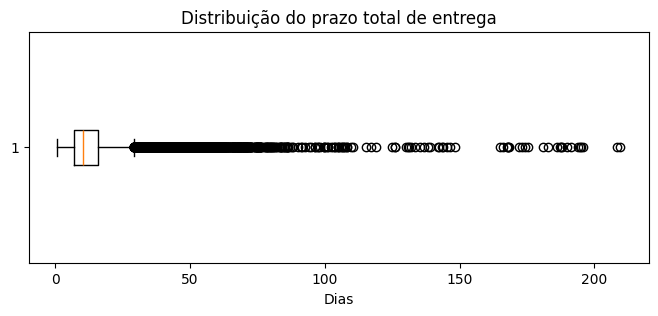

In [69]:
limite = entregues["dias_total"].quantile(0.99)
entregues["outlier"] = entregues["dias_total"] > limite

print(f"99º percentil do prazo total: {limite:.1f} dias")
print("Pedidos acima do 99º percentil:", entregues["outlier"].sum())
print(f"Maior prazo registrado: {entregues['dias_total'].max():.1f} dias")

plt.figure(figsize=(8, 3))
plt.boxplot(entregues["dias_total"], vert=False)
plt.title("Distribuição do prazo total de entrega")
plt.xlabel("Dias")
plt.show()

## 4. Entrega no prazo (OTD)

#### Prazo prometido

In [70]:
entregues["prazo_prometido"] = dias(entregues["order_estimated_delivery_date"], entregues["order_purchase_timestamp"])

#### Atraso

In [71]:
data_real = entregues["order_delivered_customer_date"].dt.normalize()
data_prometida = entregues["order_estimated_delivery_date"].dt.normalize()

entregues["dias_atraso"] = (data_real - data_prometida).dt.days

#### OTD

In [72]:
entregues["no_prazo"] = entregues["dias_atraso"] <= 0

otd = entregues["no_prazo"].mean() * 100

print(f"OTD: {otd:.1f}%")
print(f"Pedidos atrasados: {100 - otd:.1f}%")
print(f"Prazo prometido médio: {entregues['prazo_prometido'].mean():.1f} dias")
print(f"Entrega real média: {entregues['dias_total'].mean():.1f} dias")
print(f"Atraso médio (só dos atrasados): {entregues.loc[~entregues['no_prazo'], 'dias_atraso'].mean():.1f} dias")

OTD: 93.2%
Pedidos atrasados: 6.8%
Prazo prometido médio: 23.7 dias
Entrega real média: 12.6 dias
Atraso médio (só dos atrasados): 10.6 dias


#### Gráfico

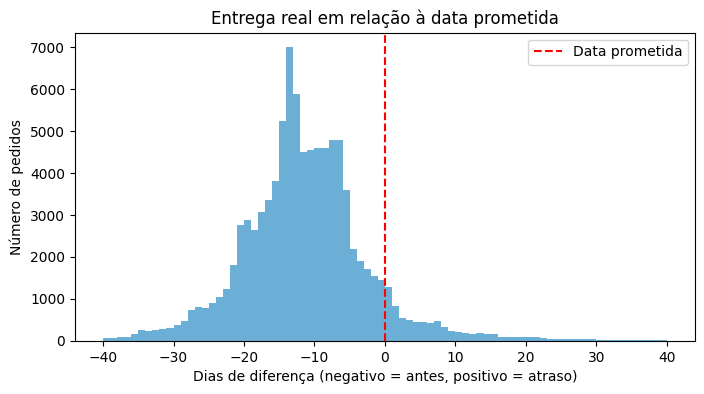

In [75]:
plt.figure(figsize=(8, 4))
plt.hist(entregues["dias_atraso"], bins=range(-40, 41), color="#6baed6")
plt.axvline(0, color="red", linestyle="--", label="Data prometida")
plt.title("Entrega real em relação à data prometida")
plt.xlabel("Dias de diferença (negativo = antes, positivo = atraso)")
plt.ylabel("Número de pedidos")
plt.legend()
plt.show()

## 5. Lead time por fase

#### Tabela com média, mediana e P90

In [76]:
fases = ["dias_aprovacao", "dias_postagem", "dias_transporte", "dias_total"]

resumo = entregues[fases].agg(["mean", "median", lambda x: x.quantile(0.90)]).round(1)
resumo.index = ["Média", "Mediana", "P90"]
resumo

,dias_aprovacao,dias_postagem,dias_transporte,dias_total
Média,0.4,2.9,9.4,12.6
Mediana,0.0,1.8,7.1,10.3
P90,1.4,6.0,18.9,23.2


#### Peso de cada fase no prazo total

In [77]:
medianas = entregues[["dias_aprovacao", "dias_postagem", "dias_transporte"]].median()
percentual = (medianas / medianas.sum() * 100).round(1)

print("Participação de cada fase (pela mediana):")
print(percentual)

Participação de cada fase (pela mediana):
dias_aprovacao      0.2
dias_postagem      20.6
dias_transporte    79.2
dtype: float64


#### Gráfico de mediana e P90 por fase

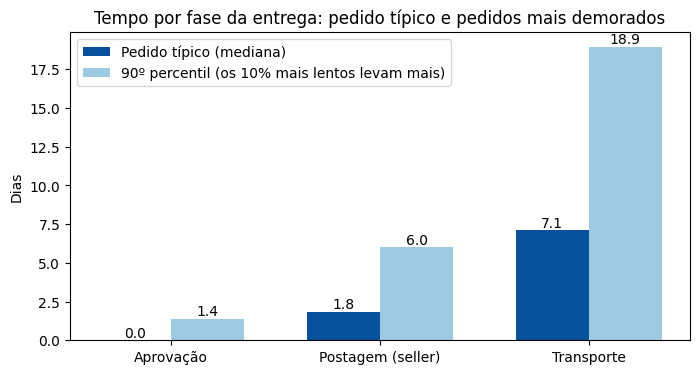

In [79]:
nomes = ["Aprovação", "Postagem (seller)", "Transporte"]
colunas = ["dias_aprovacao", "dias_postagem", "dias_transporte"]

medianas = entregues[colunas].median()
p90 = entregues[colunas].quantile(0.90)

posicao = np.arange(len(nomes))
largura = 0.35

plt.figure(figsize=(8, 4))
plt.bar(posicao - largura/2, medianas.values, largura, label="Pedido típico (mediana)", color="#08519c")
plt.bar(posicao + largura/2, p90.values, largura, label="90º percentil (os 10% mais lentos levam mais)", color="#9ecae1")

for i in range(len(nomes)):
    plt.text(posicao[i] - largura/2, medianas.values[i] + 0.2, f"{medianas.values[i]:.1f}", ha="center")
    plt.text(posicao[i] + largura/2, p90.values[i] + 0.2, f"{p90.values[i]:.1f}", ha="center")

plt.xticks(posicao, nomes)
plt.title("Tempo por fase da entrega: pedido típico e pedidos mais demorados")
plt.ylabel("Dias")
plt.legend()
plt.show()